In [9]:
from qpd_mps.decomposition import MitaraiFujiDecomposition
from qpd_mps.mps_simulation import MPSSimulationAnalyzer

from qiskit import QuantumCircuit 
import matplotlib.pyplot as plt

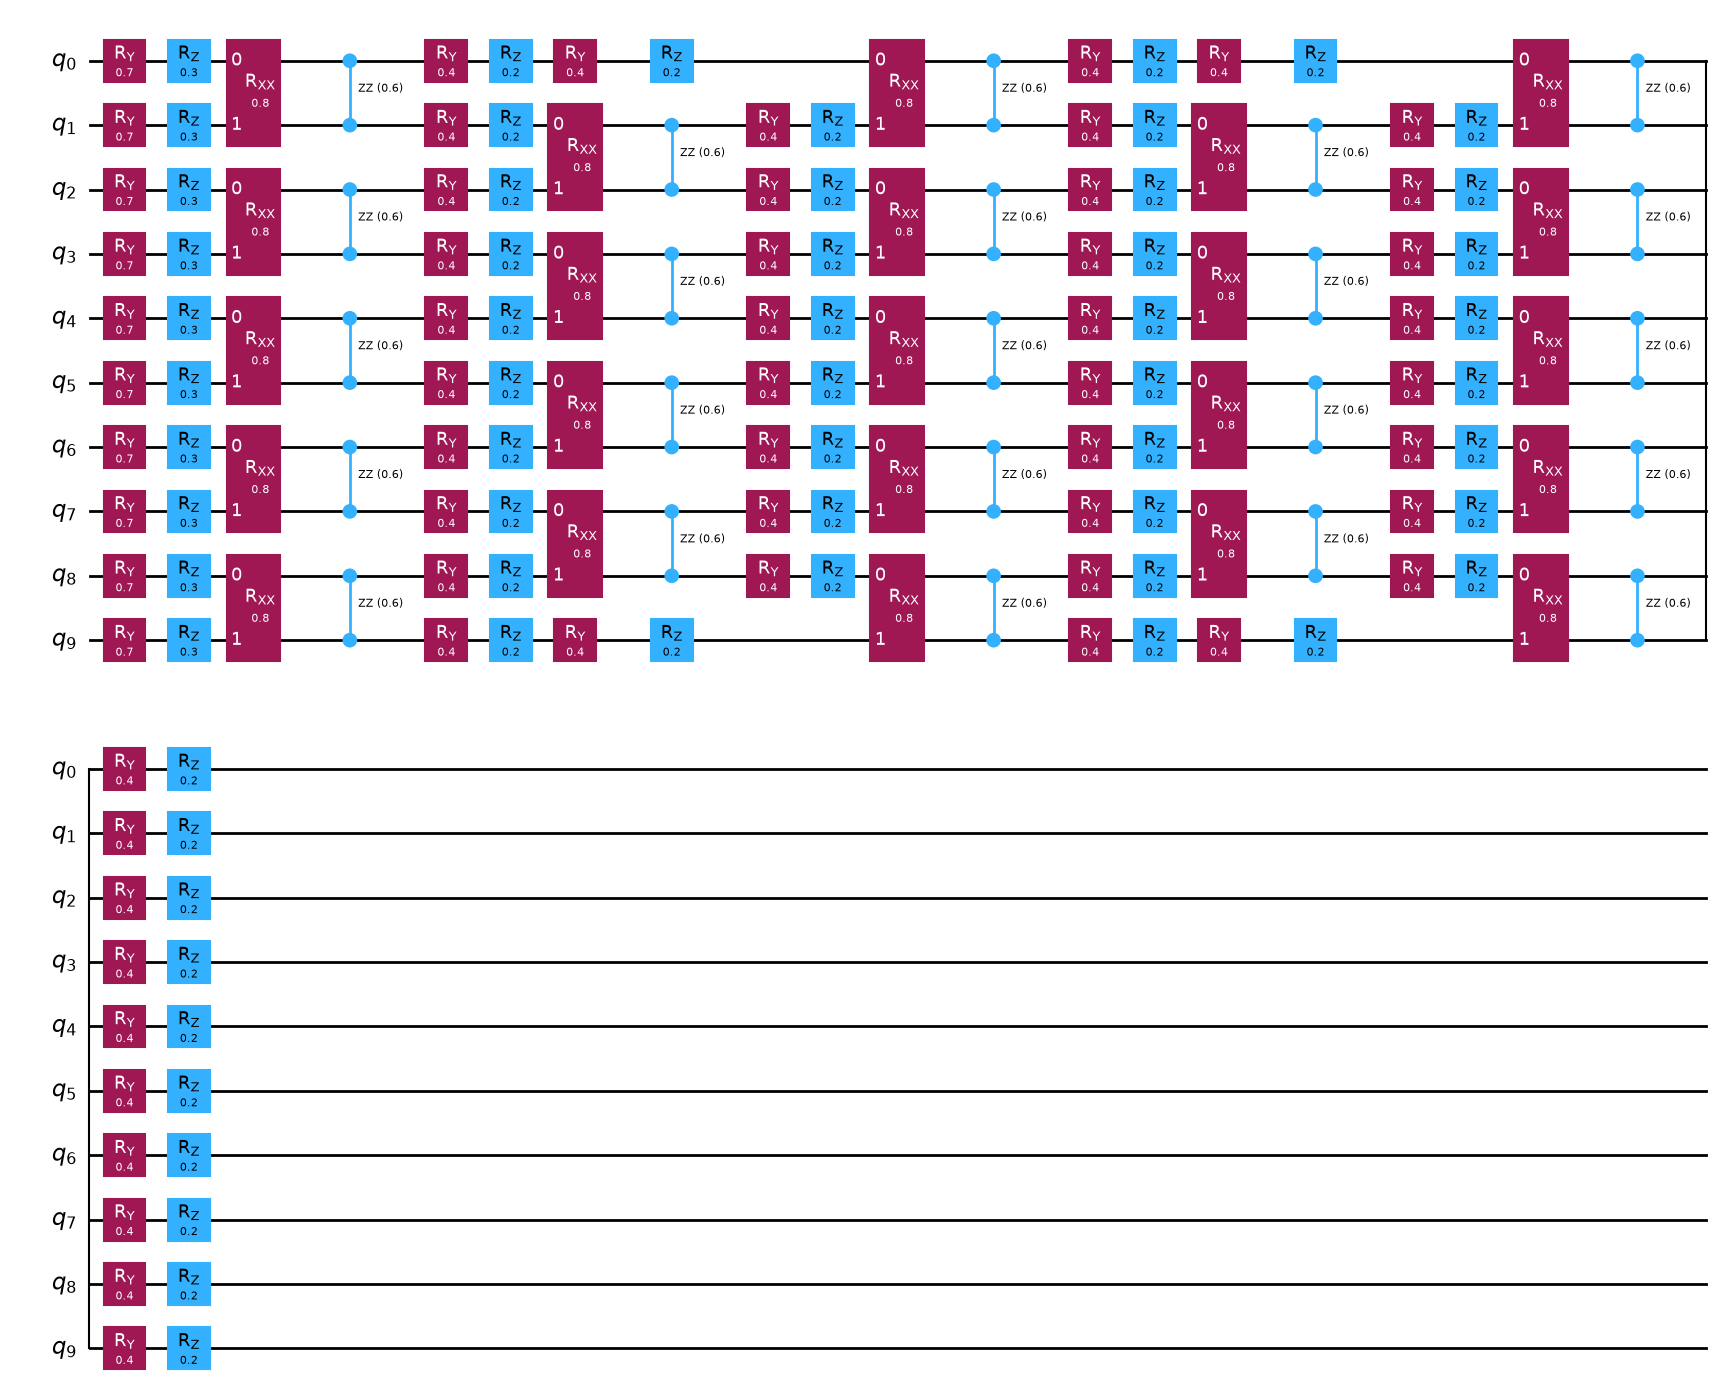

In [17]:
n = 10
layers = 5

qc = QuantumCircuit(n)

# Initial superposition
for q in range(n):
    qc.ry(0.7, q)
    qc.rz(0.3, q)

# Alternating entangling layers
for layer in range(layers):

    # Even bonds
    if layer % 2 == 0:
        for q in range(0, n - 1, 2):
            qc.rxx(0.8, q, q + 1)
            qc.rzz(0.6, q, q + 1)

    # Odd bonds
    else:
        for q in range(1, n - 1, 2):
            qc.rxx(0.8, q, q + 1)
            qc.rzz(0.6, q, q + 1)

    for q in range(n):
        qc.ry(0.4, q)
        qc.rz(0.2, q)

qc.draw('mpl')

In [21]:
decomposer = MitaraiFujiDecomposition(decom_percent=25, epsilon=0.05)
analyser = MPSSimulationAnalyzer(qc, decomposer, n_trajectories=100, max_shots=100_000)
report = analyser.analyze()
print(report.summary())

Qubits                          : 10
--- MPS (original, uncut) ---
  Max bond dimension            : 32
  Avg bond dimension            : 10.222
  Memory                        : 43.34 KiB
--- MPS (decomposed, 100 trajectories) ---
  Max bond dimension (worst)    : 8
  Max bond dimension (mean±std) : 3.86 ± 0.99
  Avg bond dimension (mean)     : 2.441
  Memory (mean / peak)          : 2.03 / 4.55 KiB
  Bond reduction (max)          : 4.00x
  Memory reduction              : 21.36x
  RSS delta (trajectory loop)   : 2.73 MiB
--- QPD ---
  Cut rotations                 : 23
  kappa                         : 35430479.3210
  Sampling overhead (kappa^2)   : 1.255e+15
  Optimal shots (eps, delta)    : 3704575975311693824
  Shots used                    : 100000  (CAPPED)
--- Observable ---
  Reconstructed estimate        : -27635.773870 ± 1.12e+05
  Reference (original circuit)  : 0.24944802804744687
  Abs. error                    : 2.764e+04
  Error in std errors           : 0.25
  Hoeffding